Compose a graphic of a sliced kiwi fruit.

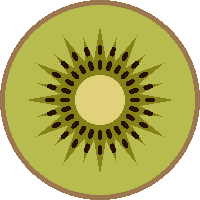

### Kiwi Seed

In our graphic, the small seeds of the kiwi are distributed in two rings.
They are dark (the color is already defined in `SEED_COLOR`)
and have an elliptical shape (about 2/3 as wide as long).

Implement the `kiwi_seed` function.
Use <API>ellipse</API>.

In [ ]:
from pytamaro import rgb_color, ellipse, show_graphic, Graphic

SEED_COLOR = rgb_color(41, 16, 3)

def kiwi_seed(diameter: float) -> Graphic:
    return #TODO

show_graphic(kiwi_seed(60))

In [3]:
#teacher-only
from pytamaro import rgb_color, ellipse, show_graphic, Graphic

SEED_COLOR = rgb_color(41, 16, 3)

def kiwi_seed(diameter: float) -> Graphic:
    return ellipse(diameter, diameter / 2, SEED_COLOR)

show_graphic(kiwi_seed(60))

### Sliced Kiwi Base

Compose a sliced kiwi without any seeds and without the core.
Use the given colors for the brownish skin (`SKIN_COLOR`),
and the greenish flesh (`FLESH_COLOR`).
The kiwi should have the given overall `diameter`
and the flesh should be 95% of that diameter.

In [ ]:
from pytamaro import overlay

SKIN_COLOR = rgb_color(156, 118, 79)
FLESH_COLOR = rgb_color(184, 188, 79)

def sliced_kiwi_base(diameter:float) -> Graphic:
    return #TODO

show_graphic(sliced_kiwi_base(200))

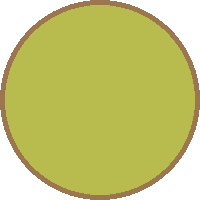

In [5]:
#teacher-only
from pytamaro import overlay

SKIN_COLOR = rgb_color(156, 118, 79)
FLESH_COLOR = rgb_color(184, 188, 79)

def sliced_kiwi_base(diameter:float) -> Graphic:
    return overlay(
        ellipse(diameter * 0.95, diameter * 0.95, FLESH_COLOR),
        ellipse(diameter, diameter, SKIN_COLOR)
    )

show_graphic(sliced_kiwi_base(200))

### Ring of Seeds

Create a function `ring` that produces a ring of `count` seeds, evenly spread across the 360 degrees of a circle.
The inside diameter of the ring should correspond to `diameter`
(the seeds should form a ring just outside the diameter).
Repetitively call `kiwi_seed` to produce the ring of seeds.

Hint: If you need help, check out the <b>Sliced Pitaya</b> activity.

In [ ]:
from pytamaro import empty_graphic, rotate, pin, beside, rectangle, black, center_left, compose

def ring(count: int, ringDiameter: float, seed: Graphic) -> Graphic:
    result = empty_graphic()
    #TODO
    return result

show_graphic(ring(24, 100, kiwi_seed(10)))

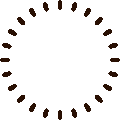

In [7]:
#teacher-only
from pytamaro import empty_graphic, rotate, pin, beside, rectangle, black, center_left, compose

def ring(count: int, ringDiameter: float, seed: Graphic) -> Graphic:
    result = empty_graphic()
    for i in range(count):
        angle = 360.0 / count * i
        s = rotate(
            angle,
            pin(
                center_left,
                beside(
                    rectangle(ringDiameter / 2, 0, black),
                    seed
                )
            )
        )
        result = compose(result, s)
    return result

show_graphic(ring(24, 100, kiwi_seed(10)))


### Ring of Triangles

The inside of a kiwi, around the seeds, is slightly darker.
We can compose this darker area using two rings of triangles.

Each ring consists of isoceles triangles with the given side length and a 20 degree angle.

Before creating a ring, implement the `kiwi_triangle` function to construct a single triangle.

In [8]:
from pytamaro import center_left, triangle

TRIANGLE_COLOR = rgb_color(132, 129, 24)

def kiwi_triangle(side: float) -> Graphic:
    return pin(
        center_left, 
        rotate(
            180 - 10, 
            triangle(side, side, 20, TRIANGLE_COLOR)
        )
    )

show_graphic(kiwi_triangle(60))

**Insight**:
To create a ring of triangles we can use the `ring` function we originally wrote to create seed rings. It doesn't really matter what graphic we repeat in the ring: a seed, or a triangle, or anything else! This is great **code reuse**!

Here is a ring consisting of 12 triangles, with a ring diameter of 50 and a triangle side length of 25:

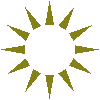

In [12]:

show_graphic(ring(12, 50, kiwi_triangle(25)))

### Sliced Kiwi
Now we have all the ingredients for our sliced kiwi.
The kiwi consists of the `sliced_kiwi_base`, two `ring`s of `kiwi_triangle`s, two `ring`s of `kiwi_seed`s, and a core circle.

Each seed ring is composed of 24 seeds, with a seed diameter of 5% of the kiwi diameter:

* ring diameter: 30% of kiwi diameter
* ring diameter: 45% of kiwi diameter

Each triangle ring is composed of 12 triangles and has a ring diameter of 25% of the kiwi's diameter:

* side 20% of the kiwi's diameter, rotated by 1/24 a triangle's angle
* side 25% of the kiwi's diameter

Place all rings on top of the kiwi base, and place a core circle (with 25% of the kiwi diameter) on top.

In [ ]:
CORE_COLOR = rgb_color(225, 209, 123)

def sliced_kiwi(diameter: float) -> Graphic:
    return #TODO

show_graphic(sliced_kiwi(200))

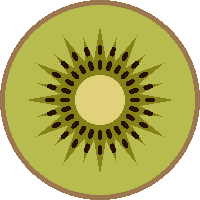

In [16]:
#teacher-only
from pytamaro import save_graphic

CORE_COLOR = rgb_color(225, 209, 123)

def sliced_kiwi(diameter: float) -> Graphic:
    return compose(
        ellipse(diameter * 0.25, diameter * 0.25, CORE_COLOR),
        compose(
            ring(24, diameter * 0.3, kiwi_seed(diameter * 0.05)),
            compose(
                ring(24, diameter * 0.45, kiwi_seed(diameter * 0.05)),
                compose(
                    rotate(360 / 24, ring(12, diameter * 0.25, kiwi_triangle(diameter * 0.2))),
                    compose(
                        ring(12, diameter * 0.25, kiwi_triangle(diameter * 0.25)),
                        sliced_kiwi_base(diameter)
                    )
                )
            )
        )
    )

show_graphic(sliced_kiwi(200))
save_graphic("sliced-kiwi.svg", sliced_kiwi(200))